# Day 2 — YOLO26n, phiên chạy local trên Mac

Học viên: Lê Quang Khải, 2A202603237, L2. Đây là phiên chạy **local**, không phải phiên Colab.

Theo thông tin học viên cung cấp ngày 10/11/2026, Lab Coach cho phép tiếp tục khi F1 thấp nếu làm đủ các bước. Annotation F1 vẫn được báo cáo nguyên giá trị, không đổi `passed` thành true.

Giữ nguyên 50 ảnh train và 10 ảnh eval của đề. Thay đổi để chạy Mac: dùng dữ liệu repo có sẵn, batch=4, device=MPS (hoặc CPU), workers=0, amp=False. Model YOLO26n, 50 epoch, imgsz=640, seed=20260909 giữ theo notebook gốc.


## Chạy lại
Chạy từ thư mục notebooks trong repo hoặc đặt biến môi trường DAY2_LAB_ROOT trỏ tới repo. Môi trường cần Ultralytics, PyTorch, matplotlib, ipykernel. Kết quả trong outputs/; checkpoint không đưa lên GitHub.


In [1]:
from pathlib import Path
import json, os, shutil, subprocess, sys, platform
os.environ.pop('ULTRALYTICS_API_KEY', None)
import torch, yaml, ultralytics
from ultralytics import YOLO, settings
settings.update({'api_key': ''})
settings.update({key:False for key in ('sync','wandb','mlflow','comet','clearml','dvc','raytune','tensorboard') if key in settings})
torch.set_num_threads(2)
LAB_ROOT = Path(os.environ.get('DAY2_LAB_ROOT', '..')).resolve()
assert (LAB_ROOT / 'dataset/images/train').is_dir(), 'DAY2_LAB_ROOT phải trỏ tới repo bài lab.'
DATA_YAML = LAB_ROOT / 'outputs/data-local.yaml'
DATA_YAML.parent.mkdir(exist_ok=True)
_data_cfg = yaml.safe_load((LAB_ROOT / 'data.yaml').read_text())
_data_cfg['path'] = str((LAB_ROOT / 'dataset').resolve())
DATA_YAML.write_text(yaml.safe_dump(_data_cfg, allow_unicode=True, sort_keys=False))
TRAIN_IMAGES = LAB_ROOT / 'dataset/images/train'
TRAIN_LABELS = LAB_ROOT / 'dataset/labels/train'
EVAL_IMAGES = LAB_ROOT / 'dataset/images/eval'
EVAL_LABELS = LAB_ROOT / 'dataset/labels/eval'
RUNS = LAB_ROOT / 'outputs/yolo26_runs'
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
summary_qc = json.loads((LAB_ROOT / 'outputs/annotation_evaluation.json').read_text())
print('Annotation QC:', {key: summary_qc[key] for key in ('f1','mean_iou_of_matches','passed')})
print('Tiếp tục theo hướng dẫn Lab Coach do học viên cung cấp: F1 thấp được ghi nhận thật.')
print('Runtime:', platform.platform(), 'Python', platform.python_version(), 'Ultralytics', ultralytics.__version__, 'Torch', torch.__version__, 'device', DEVICE)

def write_progress(phase, **extra):
    target=LAB_ROOT / 'outputs/pipeline-progress.json'
    temp=target.with_suffix('.tmp')
    temp.write_text(json.dumps({'phase':phase,**extra},ensure_ascii=False))
    temp.replace(target)
write_progress('setup')


Annotation QC: {'f1': 0.4895, 'mean_iou_of_matches': 0.8335, 'passed': False}
Tiếp tục theo hướng dẫn Lab Coach do học viên cung cấp: F1 thấp được ghi nhận thật.
Runtime: macOS-26.5.2-arm64-arm-64bit-Mach-O Python 3.14.10 Ultralytics 8.4.208 Torch 2.15.0 device mps


In [2]:
def image_stems(directory):
    return {p.stem for ext in ('*.jpg', '*.jpeg', '*.png') for p in directory.glob(ext)}

train_images = image_stems(TRAIN_IMAGES)
train_labels = {p.stem for p in TRAIN_LABELS.glob('*.txt')}
eval_images = image_stems(EVAL_IMAGES)
eval_labels = {p.stem for p in EVAL_LABELS.glob('*.txt')}
assert len(train_images) == 50, f' cần 50 train images, thấy {len(train_images)}'
assert train_images == train_labels, f'train images/labels lệch: {sorted(train_images ^ train_labels)[:5]}'
assert len(eval_images) == 10 and eval_images == eval_labels, 'eval phải đủ 10 ảnh và nhãn'
print(f'OK: {len(train_images)} train + {len(eval_images)} eval; eval không đi vào train.')

OK: 50 train + 10 eval; eval không đi vào train.


## Huấn luyện

Bài thực hành dùng checkpoint `yolo26n.pt`. Với 50 ảnh, dùng model nano và ít epoch để minh họa vòng lặp dữ liệu; thời gian/metric không dùng làm benchmark sản phẩm.

In [3]:
write_progress('loading_model')
model = YOLO(str(LAB_ROOT / 'outputs/yolo26n.pt'))
def on_epoch(trainer):
    write_progress('training', epoch=trainer.epoch+1, epochs=50)
model.add_callback('on_fit_epoch_end', on_epoch)
train_result = model.train(
    data=str(DATA_YAML), epochs=50, imgsz=640, batch=4, device=DEVICE,
    workers=0, amp=False, project=str(RUNS), name='vehicle_annotation',
    exist_ok=False, seed=20260909, plots=True,
)
BEST = Path(model.trainer.best)
print('best checkpoint:', BEST)
write_progress('trained', checkpoint=str(BEST))


Ultralytics 8.4.208 🚀 Python-3.14.10 torch-2.15.0 MPS (Apple M5)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/data-local.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/yolo26n.pt, momentum=0.937, mosaic=1.0, mult

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (998 outputs left out)

                   van          6         12      0.197     0.0833      0.111     0.0929


Speed: 0.3ms preprocess, 21.9ms inference, 0.0ms loss, 1.8ms postprocess per image


Results saved to /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/yolo26_runs/vehicle_annotation


best checkpoint: /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/yolo26_runs/vehicle_annotation/weights/best.pt


## Đánh giá đúng tập eval

`data.yaml` trỏ `val` tới 10 ảnh eval đã có nhãn. Không đổi `val` sang train để làm đẹp mAP. Ghi lại mAP50, mAP50-95, precision và recall.

Tập `eval` cũng được dùng làm validation trong quá trình train và chọn `best.pt`, nên không phải test set độc lập.

In [4]:
write_progress("evaluating")
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='val', device=DEVICE, plots=True, project=str(RUNS), name='vehicle_eval', exist_ok=True)
summary = {
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50),
    'map50_95': float(metrics.box.map),
    'eval_images': len(eval_images),
    'checkpoint': str(BEST),
}
metrics_path = LAB_ROOT / 'outputs/model_eval_metrics.json'
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

Ultralytics 8.4.208 🚀 Python-3.14.10 torch-2.15.0 MPS (Apple M5)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3291.5±228.4 MB/s, size: 75.3 KB)


val: Scanning /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/labels/eval.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 8.4Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.2it/s 0.1s

                   all         10        113      0.454      0.233      0.277      0.206


... (3 outputs left out)

                   van          6         12      0.197     0.0833      0.111     0.0929


Speed: 0.2ms preprocess, 7.6ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/yolo26_runs/vehicle_eval


{
  "precision": 0.4539938569417872,
  "recall": 0.23262616952248463,
  "map50": 0.2774763761169164,
  "map50_95": 0.2061575561120576,
  "eval_images": 10,
  "checkpoint": "/Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/yolo26_runs/vehicle_annotation/weights/best.pt"
}


In [5]:
write_progress("predicting")
# Lưu dự đoán trên đúng 10 ảnh eval.
prediction_dir = LAB_ROOT / 'outputs/eval_predictions'
results = best_model.predict(source=str(EVAL_IMAGES), conf=0.25, device=DEVICE, save=True, project=str(prediction_dir), name='visuals', exist_ok=True)
PRED_SAVE_DIR = Path(results[0].save_dir)
print('predictions saved to:', PRED_SAVE_DIR)

# Chỉ thêm hai thư mục kết quả và metrics; không đưa chính ZIP hoặc checkpoint vào ZIP.
import zipfile
archive = LAB_ROOT / 'outputs/day2_colab_outputs.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in (prediction_dir, RUNS):
        for path in sorted(folder.rglob('*')):
            if path.is_file() and path.suffix.lower() != '.pt':
                z.write(path, Path('day2_colab_outputs') / path.relative_to(LAB_ROOT / 'outputs'))
    z.write(metrics_path, 'day2_colab_outputs/model_eval_metrics.json')
print('Đã tạo:', archive)


image 1/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_051.jpg: 640x640 12 cars, 1 bus, 2 vans, 3.4ms


image 2/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_052.jpg: 640x640 18 cars, 3 buss, 3.8ms


image 3/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_053.jpg: 640x640 12 cars, 1 bus, 3.7ms


image 4/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_054.jpg: 640x640 4 cars, 2 vans, 3.5ms


image 5/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_055.jpg: 640x640 5 cars, 3.7ms


image 6/10 /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/dataset/images/eval/drive_056.jpg: 640x640 19 cars, 1 bus, 1 van, 3.7ms


... (4 outputs left out)

Speed: 0.9ms preprocess, 3.6ms inference, 4.8ms postprocess per image at shape (1, 3, 640, 640)


Results saved to /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/eval_predictions/visuals


predictions saved to: /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/eval_predictions/visuals


Đã tạo: /Users/phambaovy/Applications/vscode/vf/linh tinh/K5-L2-Day02-ObjectDetection/outputs/day2_colab_outputs.zip


## Xem trực tiếp kết quả dự đoán

Hiển thị 10 ảnh eval kèm box dự đoán ngay trong notebook, không cần tải file `.zip` về mới xem được.

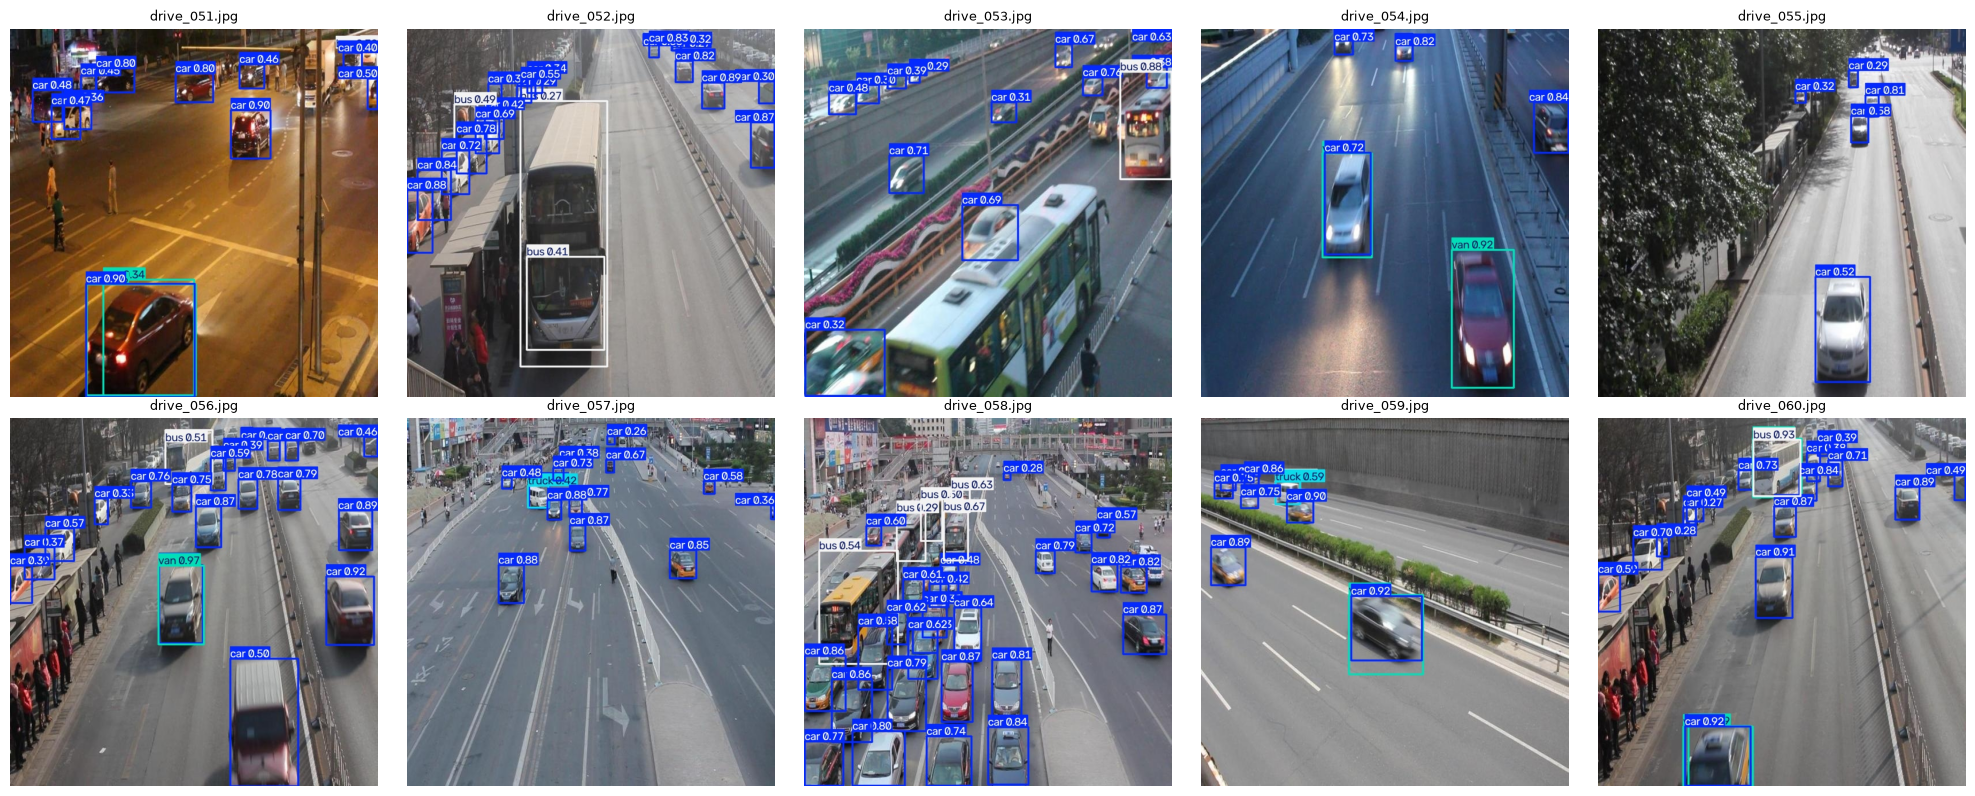

In [6]:
import math
import matplotlib.pyplot as plt
from PIL import Image

pred_images = sorted(PRED_SAVE_DIR.glob('*.jpg'))
cols = 5
rows = math.ceil(len(pred_images) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax, img_path in zip(axes.flat, pred_images):
    ax.imshow(Image.open(img_path))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(pred_images):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
write_progress("complete", metrics=summary, predictions=len(pred_images))


## Câu hỏi phân tích để nộp

1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.
2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
4. Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?